# 8.2 Тип графика под вопрос — код страницы

Аналитика 101 · блок «Дата аналитика» · тема 08 «Визуализация в Python» · страница 8.2.

В ноутбуке три блока кода раздела «Код» с рисунками: четыре вопроса и четыре графика на одних данных, малые множители через `FacetGrid`, круговая диаграмма против столбцов. Данные учебные: продажи магазина из общего набора темы `data/viz/`.

Четыре рисунка из раздела «Нюансы» строит скрипт `nuances.py`, он лежит рядом.

**Как работать.** Выполняйте ячейки по порядку сверху вниз. Каждый блок читает данные сам, так что после первой ячейки их можно запускать и по отдельности.

Вывод получен на Python 3.13, NumPy 2.5, pandas 3.0, matplotlib 3.10 и seaborn 0.13.

## Где лежат данные

Код страницы читает файл по пути от корня папки с материалами: `data/viz/sales_monthly.csv`. Ноутбук лежит в папке страницы, поэтому первая ячейка поднимается до папки, в которой есть `data/`, и делает её рабочей. Туда же блоки сохранят рисунки `question_to_chart.svg`, `facets.svg` и `pie_to_bars.svg`.

In [1]:
import os
import pathlib
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn

root = pathlib.Path.cwd()
while not (root / "data" / "viz").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/viz/
assert (root / "data" / "viz" / "sales_monthly.csv").exists(), \
    "Не найдена папка data/viz/. Скачайте общий набор темы 08 и положите data/ рядом с папкой страницы"
os.chdir(root)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", seaborn.__version__)

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.10.0 | seaborn 0.13.2


## Код: вопрос выбирает график

### Одна функция — четыре вопроса и четыре графика

сравнение: {'сайт': 114.2, 'маркетплейс': 77.7, 'приложение': 63.0}
динамика: пик 2025-12 41.7 | провал 2024-06 27.3
распределение: меньше 2,5 млн — 56% месяцев канала
связь: r = 0.958


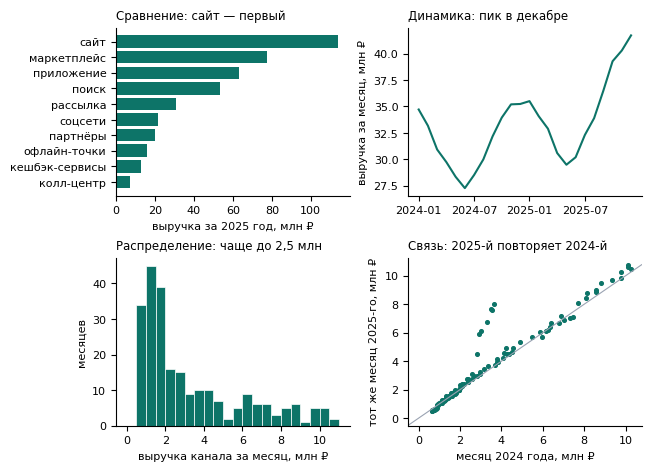

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"svg.fonttype": "none", "font.size": 8,
                     "axes.spines.top": False, "axes.spines.right": False})
ACC, GREY = "#0d7468", "#9aa3b2"

df = pd.read_csv("data/viz/sales_monthly.csv")            # длинный формат, 960 строк
wide = df.pivot_table(index="month", columns="channel",
                      values="revenue", aggfunc="sum") / 1e6  # 24 месяца × 10 каналов, млн ₽
y24, y25 = wide.loc["2024-01":"2024-12"], wide.loc["2025-01":"2025-12"]


def chart_for(question, ax):
    """Вопрос → тип графика. Данные одни и те же, меняется форма."""
    if question == "сравнение":        # кто больше → столбцы по убыванию
        s = y25.sum().sort_values()
        ax.barh(s.index, s.values, color=ACC)
        ax.set_xlabel("выручка за 2025 год, млн ₽")
    elif question == "динамика":       # как менялось → линия по времени
        total = wide.sum(axis=1)
        ax.plot(total.index, total.values, color=ACC)  # месяцы-строки идут по порядку
        ax.set_xticks(["2024-01", "2024-07", "2025-01", "2025-07"])
        ax.set_ylabel("выручка за месяц, млн ₽")
    elif question == "распределение":  # какие значения обычны → гистограмма
        ax.hist(wide.to_numpy().ravel(), bins=np.arange(0, 11.5, 0.5),
                color=ACC, edgecolor="white", linewidth=0.5)
        ax.set_xlabel("выручка канала за месяц, млн ₽")
        ax.set_ylabel("месяцев")
    elif question == "связь":          # меняется ли одно вместе с другим → рассеяние
        ax.scatter(y24.to_numpy().ravel(), y25.to_numpy().ravel(), s=7, color=ACC)
        ax.axline((0, 0), slope=1, color=GREY, linewidth=0.8)  # линия «2025 = 2024»
        ax.set_xlabel("месяц 2024 года, млн ₽")
        ax.set_ylabel("тот же месяц 2025-го, млн ₽")
    else:
        raise ValueError(f"нет графика для вопроса «{question}»")
    return ax


TITLES = {  # заголовок — вывод, а не название осей
    "сравнение": "Сравнение: сайт — первый",
    "динамика": "Динамика: пик в декабре",
    "распределение": "Распределение: чаще до 2,5 млн",
    "связь": "Связь: 2025-й повторяет 2024-й",
}
fig, axes = plt.subplots(2, 2, figsize=(6.4, 4.6), layout="constrained")
for (q, title), ax in zip(TITLES.items(), axes.flat):
    chart_for(q, ax).set_title(title, loc="left", fontsize=8.5)
fig.savefig("question_to_chart.svg")

total = wide.sum(axis=1)
values = wide.to_numpy().ravel()
print("сравнение:", y25.sum().nlargest(3).round(1).to_dict())
print("динамика: пик", total.idxmax(), round(total.max(), 1),
      "| провал", total.idxmin(), round(total.min(), 1))
print("распределение: меньше 2,5 млн —", f"{(values < 2.5).mean():.0%}", "месяцев канала")
print("связь: r =", np.corrcoef(y24.to_numpy().ravel(), y25.to_numpy().ravel())[0, 1].round(3))

На странице каждый блок — отдельный скрипт, а в ноутбуке сессия одна: первый блок убрал верхнюю и правую рамки через `rcParams`, и эта настройка действует до конца сессии. Перед следующим блоком возвращаем настройки Matplotlib по умолчанию, чтобы рисунок вышел таким же, как на странице.

In [3]:
plt.rcdefaults()

### Малые множители: приложение растёт, колл-центр угасает

channel
колл-центр       -20.0
маркетплейс       -0.2
соцсети            2.2
кешбэк-сервисы     2.7
офлайн-точки       4.5
сайт               4.6
поиск              6.5
партнёры           8.2
рассылка          11.7
приложение        65.9


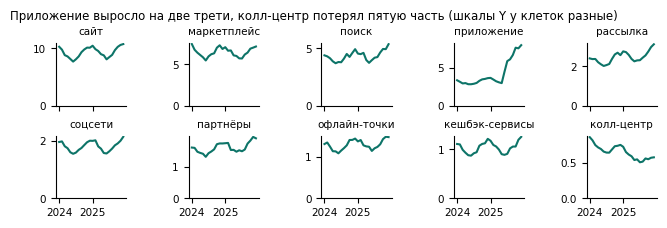

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

plt.rcParams.update({"svg.fonttype": "none", "font.size": 7.5})

df = pd.read_csv("data/viz/sales_monthly.csv")
m = df.groupby(["month", "channel"], as_index=False)["revenue"].sum()
m["млн ₽"] = m["revenue"] / 1e6
order = m.groupby("channel")["revenue"].sum().sort_values(ascending=False).index

g = sns.FacetGrid(m, col="channel", col_order=order, col_wrap=5,
                  height=1.2, aspect=1.15, sharey=False)  # у каждой клетки своя шкала Y
g.map_dataframe(sns.lineplot, x="month", y="млн ₽", color="#0d7468")
g.set_titles("{col_name}")
g.set_axis_labels("", "")
g.set(xticks=["2024-01", "2025-01"], xticklabels=["2024", "2025"], ylim=(0, None))
g.figure.suptitle("Приложение выросло на две трети, колл-центр потерял пятую часть "
                  "(шкалы Y у клеток разные)", x=0.02, ha="left", fontsize=8.5)
g.figure.subplots_adjust(top=0.84)
g.savefig("facets.svg")

y = m.assign(year=m["month"].str[:4]).pivot_table(
    index="channel", columns="year", values="млн ₽", aggfunc="sum")
print((y["2025"] / y["2024"] - 1).mul(100).round(1).sort_values().to_string())

In [5]:
plt.rcdefaults()

### Круг становится столбцами, и приложение видно третьим

channel
сайт              27.4
маркетплейс       18.7
приложение        15.1
поиск             12.8
рассылка           7.4
соцсети            5.2
партнёры           4.8
офлайн-точки       3.8
кешбэк-сервисы     3.0
колл-центр         1.7


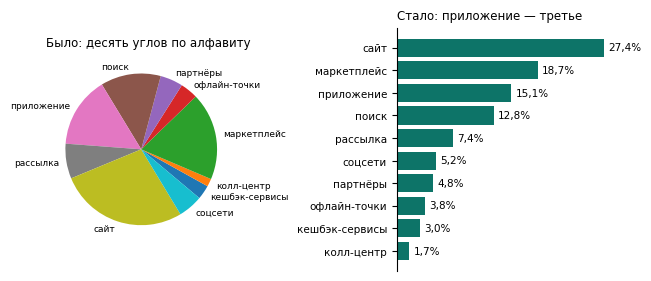

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"svg.fonttype": "none", "font.size": 7.5})

df = pd.read_csv("data/viz/sales_monthly.csv")
y25 = df[df["month"].str.startswith("2025")]
s = y25.groupby("channel")["revenue"].sum() / 1e6     # млн ₽, каналы по алфавиту
share = s / s.sum() * 100

fig, (left, right) = plt.subplots(1, 2, figsize=(6.4, 2.7), layout="constrained",
                                  width_ratios=[1, 1.15])
left.pie(s, labels=s.index, startangle=-40, textprops={"fontsize": 6.5})  # доли в порядке groupby
left.set_title("Было: десять углов по алфавиту", loc="left", fontsize=8.5)

top = share.sort_values()                              # по возрастанию: крупный канал окажется наверху
bars = right.barh(top.index, top.values, color="#0d7468")
right.bar_label(bars, labels=[f"{v:.1f}%".replace(".", ",") for v in top], padding=3)
right.set_xticks([])                                   # подписи на столбцах заменяют ось
right.spines[["top", "right", "bottom"]].set_visible(False)
right.set_title("Стало: приложение — третье", loc="left", fontsize=8.5)
fig.savefig("pie_to_bars.svg")

print(share.sort_values(ascending=False).round(1).to_string())